In [1]:
load("visualize.sage")
load("surfaces.sage")
load("curves.sage")
load("subresultants.sage")

In [25]:
degree = 6
order = '2+2+2'

v=['a%d' % i for i in xrange(degree +1)]
v.append('t')
R=PolynomialRing(QQ, v)
R.inject_variables()
poly = sum([R('a%d' %i) *t ^i for i in range(degree +1)]).polynomial(t)

poly_d = poly.derivative()

S0 = subrescoefs(poly, poly_d, 0)
S1 = subrescoefs(poly, poly_d, 1)
S2 = subrescoefs(poly, poly_d, 2)
S3 = subrescoefs(poly, poly_d, 3)


# disc:

dS = load('discriminants/disc2_2')
sub_dict = dict(zip((dS.ring()).gens(),S2))
S2disc_2 = dS.substitute(sub_dict)

dS = load('discriminants/disc3_3')
sub_dict = dict(zip((dS.ring()).gens(),S3))
S3disc_3 = dS.substitute(sub_dict)

dS = load('discriminants/disc3_2')
sub_dict = dict(zip((dS.ring()).gens(),S3))
S3disc_2 = dS.substitute(sub_dict)


if order == '2':
    disc = ideal(S0).saturation(ideal(S0[0].variables()[-1]))[0]

if order == '3':
    disc = ideal(S0)+ideal(S1)+S2disc_2
    disc = disc.saturation(S2[0])[0]
    disc = disc.saturation(ideal(S0[0].variables()[-1]))[0]

if order == '2+2':
    disc = ideal(S0[0])+ideal(S1)
    disc = disc.saturation(ideal(S0[0].variables()[-1]))[0]
    disc = disc.saturation(S2disc_2)[0]
    
if order == '4':
    disc = ideal(S0)+ideal(S1)+ideal(S2)+S3disc_3
    disc = disc.saturation(ideal(S0[0].variables()[-1]))[0]
    disc = disc.saturation(S3[0])[0]
    
if order == '3+2':
    disc = ideal(S0)+ideal(S1)+ideal(S2)+S3disc_2
    disc = disc.saturation(ideal(S0[0].variables()[-1]))[0]
    disc = disc.saturation(S3[0])[0]

if order == '2+2+2':
    disc = ideal(S0)+ideal(S1)+ideal(S2)
    disc = disc.saturation(ideal(S0[0].variables()[-1]))[0]
    disc = disc.saturation(S3disc_2)[0]
    

#nodal,cuspidal = nodal_and_cuspidal_discriminant_ideals(degree)

print disc
#print nodal.saturation(ideal(S0[0].variables()[-1]))[0]==disc

disc.save("discriminants/disc%d_%s" %(degree,order))

Defining a0, a1, a2, a3, a4, a5, a6, t
Ideal (5*a5^4 - 24*a4*a5^2*a6 + 16*a4^2*a6^2 + 32*a3*a5*a6^2 - 64*a2*a6^3, 2*a4*a5^3 - 8*a4^2*a5*a6 - a3*a5^2*a6 + 20*a3*a4*a6^2 - 8*a2*a5*a6^2 - 40*a1*a6^3, a3*a5^3 - 4*a3*a4*a5*a6 + 8*a3^2*a6^2 - 8*a1*a5*a6^2 - 32*a0*a6^3, a2*a5^3 - 4*a2*a4*a5*a6 + a1*a5^2*a6 + 8*a2*a3*a6^2 - 4*a1*a4*a6^2 - 16*a0*a5*a6^2, a1*a5^3 - 4*a1*a4*a5*a6 + 4*a0*a5^2*a6 + 8*a1*a3*a6^2 - 16*a0*a4*a6^2, 20*a0*a5^3 - a3^3*a6 + 4*a2*a3*a4*a6 - 8*a1*a4^2*a6 - 8*a2^2*a5*a6 + 14*a1*a3*a5*a6 - 56*a0*a4*a5*a6 + 24*a1*a2*a6^2 + 4*a0*a3*a6^2, a4^2*a5^2 - 4*a4^3*a6 + 2*a3*a4*a5*a6 - 5*a2*a5^2*a6 + 5*a3^2*a6^2 + 16*a2*a4*a6^2 - 30*a1*a5*a6^2 - 20*a0*a6^3, a3*a4*a5^2 - 4*a3*a4^2*a6 + 2*a3^2*a5*a6 - 10*a1*a5^2*a6 + 16*a2*a3*a6^2 - 40*a0*a5*a6^2, a2*a4*a5^2 - 4*a2*a4^2*a6 + 2*a2*a3*a5*a6 - 25*a0*a5^2*a6 + 16*a2^2*a6^2 - 10*a1*a3*a6^2 + 20*a0*a4*a6^2, 4*a1*a4*a5^2 + a3^3*a6 - 4*a2*a3*a4*a6 - 8*a1*a4^2*a6 + 8*a2^2*a5*a6 - 6*a1*a3*a5*a6 - 24*a0*a4*a5*a6 + 40*a1*a2*a6^2 - 4*a0*a3*a6^2, a0*a4

# Plane curves

We consider a general curve $\mathbb P^2$ of degree $d$.

Ideal (-x0^4 - x0^3*x1 - 3*x0^2*x1^2 - x0*x1^3 + 2*x1^4 - x0^2*x1*x2 - 4*x0*x1^2*x2 - x1^3*x2 + x0*x1*x2^2 + 2*x1^2*x2^2 + x0*x2^3 - x1*x2^3 + 2*x2^4) of Multivariate Polynomial Ring in x0, x1, x2 over Rational Field


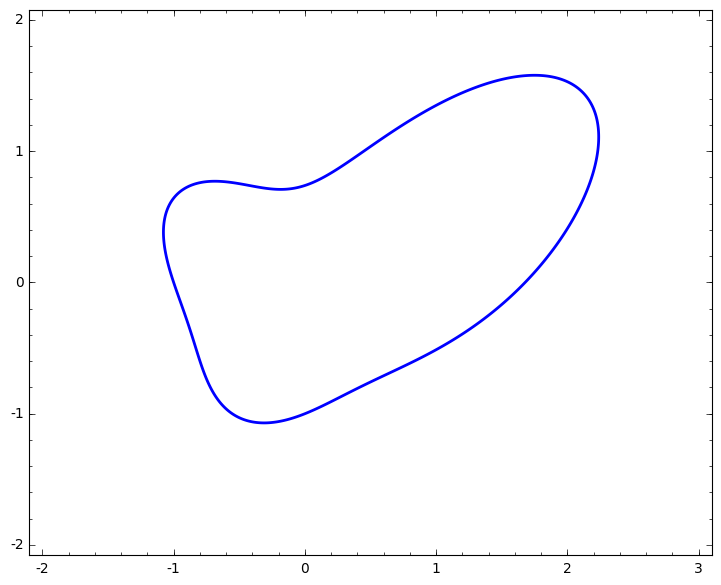

In [400]:
R.<x0,x1,x2> = QQ[]

degree = 4

F = general_curve(degree)
print F

g = plot_curve(F)
g.show()

### Inflectional and double tangents
We compute inflectional points and lines using the hessian determinant.

Number of complex flexes:  24
Number of real flexes:  6


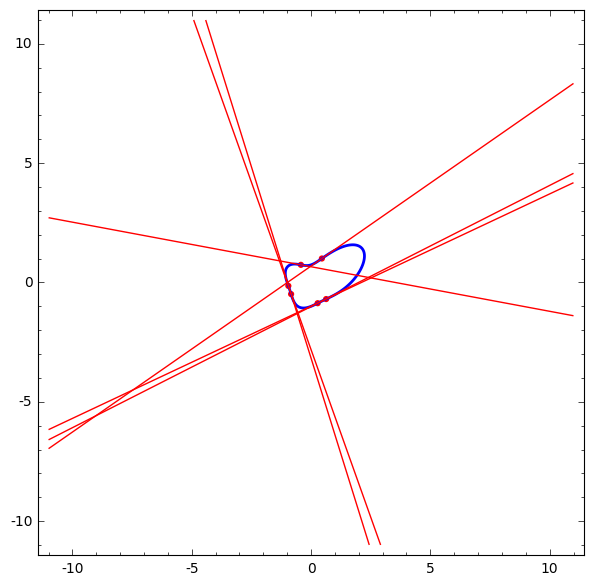

In [401]:
R.<x0,x1,x2> = QQ[]
flex_points_ideal = F + hessian_determinant(F)

print "Number of complex flexes: ", flex_points_ideal.hilbert_polynomial()

# real flex points:
real_flex_points = (flex_points_ideal.subs(x0=1).change_ring(QQ[x1, x2])).variety(RR)
print "Number of real flexes: ", len(real_flex_points)

# compute and show real flex lines
lines=tangents_at_points(F,real_flex_points)

g = plot_curve(F)
g += plot_lines(lines)
g += plot_points(real_flex_points)
g.show()

In [6]:
degree = 3

disc = discriminant_polynomial(degree)

nodal,cuspidal = nodal_and_cuspidal_discriminant_ideals(degree)

nodal.save("nodal3")
print disc
print nodal
print cuspidal

Defining a0, a1, a2, a3, t
Defining a0, a1, a2, a3, t
a1^2*a2^2 - 4*a0*a2^3 - 4*a1^3*a3 + 18*a0*a1*a2*a3 - 27*a0^2*a3^2
Ideal (a3, a1^2 - 4*a0*a2) of Multivariate Polynomial Ring in a0, a1, a2, a3 over Rational Field
Ideal (a2^2 - 3*a1*a3, a1*a2*a3 - 9*a0*a3^2, a1^2*a3 - 3*a0*a2*a3) of Multivariate Polynomial Ring in a0, a1, a2, a3 over Rational Field


Number of complex double lines:  28
Number of real double lines:  4


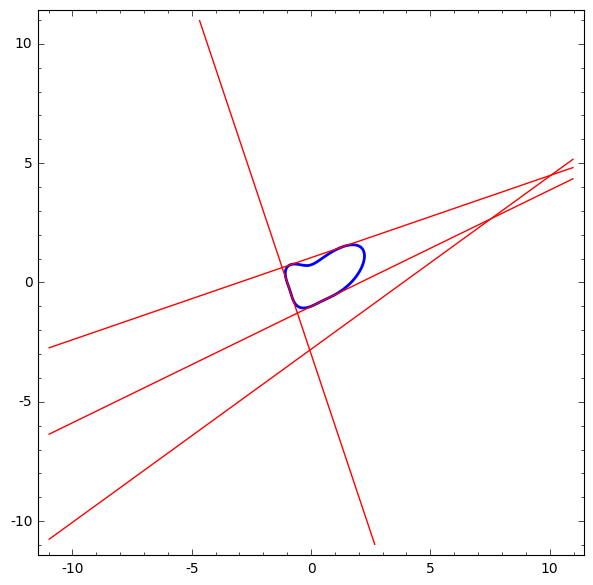

In [427]:
R2.<u0,u1,u2> = QQ[]
R3.<x0, x1, x2, u0, u1, u2, t> = QQ[]

# two points on u0x0+u1x1+u2x2=0
P = vector([-u1, u0, 0])
Q = vector([0, -u2, u1])

F1 = F.change_ring(R3)
poly = (F1.subs(x0=((P + t * Q)[0]), x1=((P + t * Q)[1]), x2=((P + t * Q)[2]))).gens()[0]

c=poly.polynomial(t).coefficients()

sub_dict = dict(zip(nodal.ring().gens(),c))

#double_lines = nodal.subs(a0=c[0],a1=c[1],a2=c[2],a3=c[3],a4=c[4]) # change
double_lines = nodal.subs(sub_dict)
double_lines = double_lines.change_ring(R2)

R2.<u0,u1,u2> = QQ[]
double_lines = double_lines.saturation(ideal(u1))[0]

print "Number of complex double lines: ", double_lines.hilbert_polynomial()

real_double_lines = (double_lines.subs(u0=1).change_ring(QQ[u1, u2])).variety(RR)
print "Number of real double lines: ", len(real_double_lines)

if True:
    lines = []
    for l in real_double_lines:
        lines.append([1,l['u1'],l['u2']])

    R.<x1,x2> = QQ[]
    g = plot_curve(F)
    for l in lines:
        line_equation = ideal(l[0] +l[1] *x1 +l[2] *x2).change_ring(RR[x1, x2])
        g += line_equation.plot(color='red')
    g.show()

### Dual curve
We can compute the *dual curve* using a similar procedure.

Degree of dual:  12
Ideal (77211*u0^12 - 111690*u0^11*u1 + 105781*u0^10*u1^2 - 72696*u0^9*u1^3 - 401893*u0^8*u1^4 + 314648*u0^7*u1^5 - 183825*u0^6*u1^6 - 121368*u0^5*u1^7 + 257957*u0^4*u1^8 - 80606*u0^3*u1^9 + 58462*u0^2*u1^10 - 41896*u0*u1^11 + 6571*u1^12 - 292320*u0^11*u2 - 2786*u0^10*u1*u2 + 146412*u0^9*u1^2*u2 - 110590*u0^8*u1^3*u2 + 1841428*u0^7*u1^4*u2 + 219812*u0^6*u1^5*u2 - 58362*u0^5*u1^6*u2 + 122346*u0^4*u1^7*u2 - 1176700*u0^3*u1^8*u2 + 527478*u0^2*u1^9*u2 - 272058*u0*u1^10*u2 + 82348*u1^11*u2 + 368884*u0^10*u2^2 + 627156*u0^9*u1*u2^2 - 703475*u0^8*u1^2*u2^2 + 115956*u0^7*u1^3*u2^2 - 2152439*u0^6*u1^4*u2^2 - 2521748*u0^5*u1^5*u2^2 + 2152649*u0^4*u1^6*u2^2 + 454332*u0^3*u1^7*u2^2 + 2343011*u0^2*u1^8*u2^2 - 496528*u0*u1^9*u2^2 + 158874*u1^10*u2^2 - 415572*u0^9*u2^3 + 7988*u0^8*u1*u2^3 + 449200*u0^7*u1^2*u2^3 + 1758426*u0^6*u1^3*u2^3 - 20338*u0^5*u1^4*u2^3 + 1306732*u0^4*u1^5*u2^3 - 7229160*u0^3*u1^6*u2^3 - 1793458*u0^2*u1^7*u2^3 - 529074*u0*u1^8*u2^3 - 710648*u1^9*u2^3 + 701522

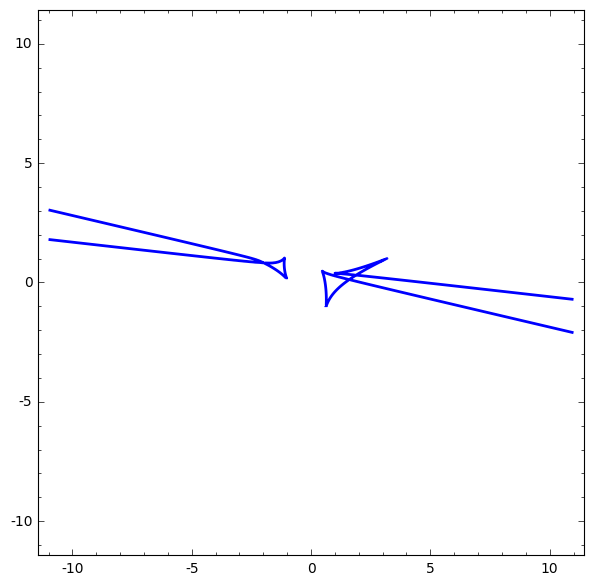

In [324]:
R2.<u0,u1,u2> = QQ[]
R3.<x0, x1, x2, u0, u1, u2, t> = QQ[]

# two points on u0x0+u1x1+u2x2=0
P = vector([-u1, u0, 0])
Q = vector([0, -u2, u1])

F1 = F.change_ring(R3)
poly = (F1.subs(x0=((P + t * Q)[0]), x1=((P + t * Q)[1]), x2=((P + t * Q)[2]))).gens()[0]
dual_curve_p = poly.discriminant(t)
dual_curve = ideal(dual_curve_p) #.change_ring(R2)

dual_curve = dual_curve.saturation(ideal(u1))[0]


print "Degree of dual: ", dual_curve.gens()[0].degree()
print dual_curve
g = plot_curve(dual_curve)
g.show()

### Summary

In [325]:
print "The curve defined by \n", F.gens()[0]
print "Degree: ", degree
print "Degree of dual: ", dual_curve.gens()[0].degree()
print "Inflection points (complex/real): ", flex_points_ideal.hilbert_polynomial(), len(real_flex_points)
print "Bitangents (complex/real): ", double_lines.hilbert_polynomial(), len(real_double_lines)

The curve defined by 
-3*x0^4 + x0^3*x1 + x0^2*x1^2 + x0*x1^3 + x1^4 - x0^3*x2 - 6*x0^2*x1*x2 + x0*x1^2*x2 - x0^2*x2^2 + 8*x1^2*x2^2 - 3*x0*x2^3 - x1*x2^3 - x2^4
Degree:  4
Degree of dual:  12
Inflection points (complex/real):  24 6
Bitangents (complex/real):  28 4


# Surfaces in $\mathbb P^3$
We consider a general surface $S$ in $\mathbb P^3$ defined by a polynomial $F \in \mathbb R[x_0,x_1,x_2,x_3]$ of degree $d$.

In [98]:
R.<x0,x1,x2,x3> = QQ['x0,x1,x2,x3']
X = matrix(R,[[x0],[x1],[x2],[x3]])

degree = 5

S_F = general_surface(degree)
F = S_F.gens()[0] 

print F

4*x0^5 + 62*x0^4*x1 + 2*x0^3*x1^2 + x0^2*x1^3 - x0*x1^4 + x1^5 - x0^4*x2 + x0^3*x1*x2 - 3*x0^2*x1^2*x2 + x0*x1^3*x2 + 5*x1^4*x2 + 2*x0^2*x1*x2^2 + x0^2*x2^3 + 4*x0*x1*x2^3 - x1^2*x2^3 - 3*x1*x2^4 + 2*x2^5 - 29*x0^4*x3 - x0^2*x1^2*x3 - x1^4*x3 - x0^3*x2*x3 + 7*x0^2*x1*x2*x3 - x0*x1^2*x2*x3 - 4*x1^3*x2*x3 - x0^2*x2^2*x3 + x0*x1*x2^2*x3 + x0*x2^3*x3 + x1*x2^3*x3 + x2^4*x3 - 5*x0^3*x3^2 - x0^2*x1*x3^2 + 4*x1^3*x3^2 - x0^2*x2*x3^2 + 35*x0*x1*x2*x3^2 - 21*x1^2*x2*x3^2 + x0*x2^2*x3^2 + x1*x2^2*x3^2 - 4*x2^3*x3^2 + x0^2*x3^3 - 4*x0*x1*x3^3 - x1^2*x3^3 - x1*x2*x3^3 + x2^2*x3^3 + 3*x1*x3^4 + x2*x3^4 - x3^5


In [307]:
plot_surf(F)

### Image contour
We observe the surface with a perspective projection.

Ideal (32768*u0^17*u1 + 124928*u0^16*u1^2 + 268800*u0^15*u1^3 + 177536*u0^14*u1^4 - 93664*u0^13*u1^5 + 10028*u0^12*u1^6 + 622448*u0^11*u1^7 + 738331*u0^10*u1^8 + 153944*u0^9*u1^9 - 206782*u0^8*u1^10 + 315226*u0^7*u1^11 + 777459*u0^6*u1^12 + 479928*u0^5*u1^13 - 97985*u0^4*u1^14 - 426*u0^3*u1^15 + 274514*u0^2*u1^16 + 177096*u0*u1^17 + 32027*u1^18 + 49152*u0^17*u2 + 387072*u0^16*u1*u2 + 1495552*u0^15*u1^2*u2 + 1757696*u0^14*u1^3*u2 + 462992*u0^13*u1^4*u2 - 738644*u0^12*u1^5*u2 + 946718*u0^11*u1^6*u2 + 2787374*u0^10*u1^7*u2 + 2327018*u0^9*u1^8*u2 + 32650*u0^8*u1^9*u2 - 296308*u0^7*u1^10*u2 + 1089482*u0^6*u1^11*u2 + 1458834*u0^5*u1^12*u2 + 504100*u0^4*u1^13*u2 + 1340*u0^3*u1^14*u2 + 97154*u0^2*u1^15*u2 + 90970*u0*u1^16*u2 + 18480*u1^17*u2 + 295424*u0^16*u2^2 + 2668928*u0^15*u1*u2^2 + 4947856*u0^14*u1^2*u2^2 + 4553048*u0^13*u1^3*u2^2 + 1027711*u0^12*u1^4*u2^2 - 269406*u0^11*u1^5*u2^2 + 1473007*u0^10*u1^6*u2^2 + 3844742*u0^9*u1^7*u2^2 + 2985188*u0^8*u1^8*u2^2 + 915520*u0^7*u1^9*u2^2 + 361683*

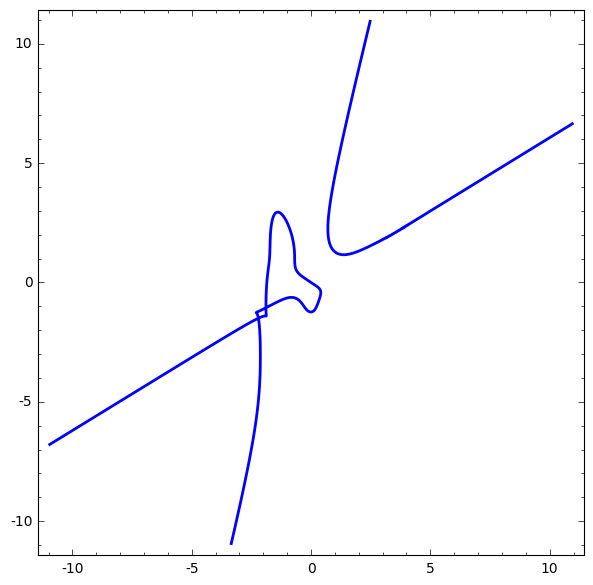

In [334]:
R2.<x0,x1,x2,x3,u0,u1,u2> = QQ['x0,x1,x2,x3,u0,u1,u2']

P = vector([1,0,0,0])
proj_matrix = matrix([[-P[1],P[0],0,0],[-P[2],0,P[0],0],[-P[3],0,0,P[0]]])

print outline

X = matrix(R2, [[x0], [x1], [x2], [x3]])
U = matrix(R2, [[u0],[u1],[u2]])
S_F = S_F.change_ring(R2)

#incidence_ideal = S_F + ideal((proj_matrix*X).augment(U).minors(2))
incidence_ideal = S_F + ideal((proj_matrix*X-U).list())

ramification = incidence_ideal + ideal(jacobian(incidence_ideal.gens(),(x0,x1,x2,x3)).minors(4))

outline = ramification.saturation(ideal(x0, x1, x2, x3))[0]
outline = outline.elimination_ideal((x0, x1, x2, x3))

g = plot_curve(outline)

g.show()

### Hurwitz complex
The Hurwitz complex is the union of tangent lines.

In [83]:
R1.<x0, x1, x2, x3, p01, p02, p03, p12, p13, p23, t> = QQ[]

# two points on u0x0+u1x1+u2x2=0
P = vector(R1,[p01,0,-p12,-p13])
Q = vector(R1,[0, p01, p02, p03])

F1 = S_F.change_ring(R1)
poly = (F1.subs(x0=((P + t * Q)[0]), x1=((P + t * Q)[1]), 
                x2=((P + t * Q)[2]), x3 =((P + t * Q)[3]))).gens()[0]


hurwitz_p = poly.discriminant(t)
hurwitz = ideal(hurwitz_p)+ideal(p01*p23-p02*p13+p03*p12) #.change_ring(R2)

hurwitz = hurwitz.saturation(ideal(p01))[0]

print "Degree of Hurwitz: ", hurwitz.gens()[1].degree()
print hurwitz

Degree of Hurwitz:  12
Ideal (p03*p12 - p02*p13 + p01*p23, 16*p01^11*p02 - 412*p01^10*p02^2 + 4168*p01^9*p02^3 - 16224*p01^8*p02^4 - 18724*p01^7*p02^5 + 241365*p01^6*p02^6 + 88056*p01^5*p02^7 - 1590204*p01^4*p02^8 - 1677218*p01^3*p02^9 - 649080*p01^2*p02^10 - 105300*p01*p02^11 - 6075*p02^12 - 48*p01^11*p03 + 1344*p01^10*p02*p03 - 14824*p01^9*p02^2*p03 + 75512*p01^8*p02^3*p03 - 225842*p01^7*p02^4*p03 + 1510738*p01^6*p02^5*p03 - 6973978*p01^5*p02^6*p03 - 5972288*p01^4*p02^7*p03 + 75947442*p01^3*p02^8*p03 + 62099946*p01^2*p02^9*p03 + 15895170*p01*p02^10*p03 + 1268460*p02^11*p03 - 960*p01^10*p03^2 + 14852*p01^9*p02*p03^2 - 94911*p01^8*p02^2*p03^2 + 276878*p01^7*p02^3*p03^2 - 2133393*p01^6*p02^4*p03^2 + 2716498*p01^5*p02^5*p03^2 + 12329953*p01^4*p02^6*p03^2 + 139377054*p01^3*p02^7*p03^2 - 1447576181*p01^2*p02^8*p03^2 - 777466134*p01*p02^9*p03^2 - 97286832*p02^10*p03^2 - 3228*p01^9*p03^3 + 968*p01^8*p02*p03^3 + 411796*p01^7*p02^2*p03^3 - 2294354*p01^6*p02^3*p03^3 + 23275510*p01^5*p02^4*p03^3

In [99]:
R1.<x0, x1, x2, x3, p01, p02, p03, p12, p13, p23, t> = QQ[]

# two points on u0x0+u1x1+u2x2=0
P = vector(R1,[1,0,-p12,-p13])
Q = vector(R1,[0, 1, p02, p03])

F1 = S_F.change_ring(R1)
poly = (F1.subs(x0=((P + t * Q)[0]), x1=((P + t * Q)[1]), 
                x2=((P + t * Q)[2]), x3 =((P + t * Q)[3]))).gens()[0]

c=poly.polynomial(t).coefficients()

disc=load('discriminants/disc5_2')

sub_dict = dict(zip((disc.ring()).gens(),c))

hurwitz = (disc.subs(sub_dict)).change_ring(R1)


hurwitz = hurwitz +ideal(1*p23-p02*p13+p03*p12) #.change_ring(R2)

hurwitz = hurwitz.saturation(ideal(p01))[0]
hurwitz = (hurwitz.homogenize(p01)).change_ring(QQ[p01, p02, p03, p12, p13, p23])

print "Degree of Hurwitz: ", hurwitz.gens()[1].degree()
print hurwitz

Degree of Hurwitz:  20
Ideal (p03*p12 - p02*p13 + p01*p23, 237112003760*p01^20 + 3500838965744*p01^19*p02 + 17174768010392*p01^18*p02^2 + 26717463928404*p01^17*p02^3 - 12397044867940*p01^16*p02^4 - 35877672396092*p01^15*p02^5 - 34715712246307*p01^14*p02^6 + 46757821529878*p01^13*p02^7 + 19385876850599*p01^12*p02^8 + 7780725212006*p01^11*p02^9 - 42178961538717*p01^10*p02^10 + 13263163328674*p01^9*p02^11 + 388263768930*p01^8*p02^12 + 9716993258020*p01^7*p02^13 - 9107938972395*p01^6*p02^14 + 2619891324952*p01^5*p02^15 - 200794194056*p01^4*p02^16 + 5464734780*p01^3*p02^17 + 757296008*p01^2*p02^18 - 106221456*p01*p02^19 + 13114464*p02^20 - 1257675895168*p01^19*p03 - 17949668026840*p01^18*p02*p03 - 85066609313740*p01^17*p02^2*p03 - 126947029391484*p01^16*p02^3*p03 + 61098031296686*p01^15*p02^4*p03 + 167045235702404*p01^14*p02^5*p03 + 149593930699080*p01^13*p02^6*p03 - 192839247415650*p01^12*p02^7*p03 - 84140489774702*p01^11*p02^8*p03 - 26088468609856*p01^10*p02^9*p03 + 149471157110242*p01^9*

### Flecnodal surface
We compute a representation of the flecnodal surface as a curve in ${\rm Gr}(1,\mathbb P^3)$.

In [ ]:
R1.<x0, x1, x2, x3, p01, p02, p03, p12, p13, p23, t> = QQ[]

# two points on u0x0+u1x1+u2x2=0
P = vector(R1,[1,0,-p12,-p13])
Q = vector(R1,[0, 1, p02, p03])

F1 = S_F.change_ring(R1)
poly = (F1.subs(x0=((P + t * Q)[0]), x1=((P + t * Q)[1]), 
                x2=((P + t * Q)[2]), x3 =((P + t * Q)[3]))).gens()[0]


c=poly.polynomial(t).coefficients()

disc4=load('discriminants/disc5_4')

sub_dict = dict(zip((disc4.ring()).gens(),c))


flecnodal = (disc4.subs(sub_dict)).change_ring(R1)

flecnodal = ideal(flecnodal)+ideal(1*p23-p02*p13+p03*p12) #.change_ring(R2)

flecnodal = flecnodal.saturation(ideal(p01))[0]

flecnodal = (flecnodal.homogenize(p01)).change_ring(QQ[p01, p02, p03, p12, p13, p23])
#print "Degree of Flecnodal: ", flecnodal.hilbert_polynomial()
print flecnodal

In [49]:
disc4=load('discriminants/disc4_4')

disc4.dimension()
disc4.ring()

Multivariate Polynomial Ring in a0, a1, a2, a3, a4 over Rational Field

We can also look at the dual $S^\vee$ in $(\mathbb P^3)^*$.

In [ ]:
R1.<x0,x1,x2,x3,u0,u1,u2,u3> = QQ['x0,x1,x2,x3,u0,u1,u2,u3']
Dual = dual_surface(S, R1)
Dual

We consider the outline of $S$ from a viewpoint $c$.

In [326]:
R2.<x0,x1,x2,x3,u0,u1,u2> = QQ['x0,x1,x2,x3,u0,u1,u2']

P = vector([1,0,0,0])
ProjMatrix = matrix([[-P[1],P[0],0,0],[-P[2],0,P[0],0],[-P[3],0,0,P[0]]])
ProjMatrix

X = matrix(R2, [[x0], [x1], [x2], [x3]])
U = matrix(R2, [[u0],[u1],[u2]])
S = S.change_ring(R2)

IncidenceIdeal = S + ideal((ProjMatrix*X).augment(U).minors(2))
#IncidenceIdeal = S + ideal((ProjMatrix*X-U).list())

Ramification = IncidenceIdeal + ideal(jacobian(IncidenceIdeal.gens(),(x0,x1,x2,x3)).minors(4))

Outline = Ramification.saturation(ideal(x0, x1, x2, x3))[0]
Outline = Outline.elimination_ideal((x0, x1, x2, x3))

Outline = Outline.subs(u0=1).change_ring(QQ['u1,u2'])

s = singular.eval
s('LIB "surf.lib";')
s("ring r = 0,(u1,u2),dp;")
s("plot("+str(Outline.gens()[0])+")")

Outline.plot()

# Outline


SingularError: Singular error:
   ? index[-1] must be positive
   ? error occurred in or before surf.lib::num_of_vars line 43: `    v[univariate(vv[i])]=1;`
   ? leaving surf.lib::num_of_vars
   skipping text from `;` error at token `)`
   ? leaving surf.lib::plot

We now consider a *variable* viewpoint $c$.

In [ ]:
R3.<x0,x1,x2,x3,u0,u1,u2,c0,c1,c2,c3> = QQ['x0,x1,x2,x3,u0,u1,u2,c0,c1,c2,c3']

P = vector([c0,c1,c2,c3])
ProjMatrix = matrix([[-P[1],P[0],0,0],[-P[2],0,P[0],0],[-P[3],0,0,P[0]]])
ProjMatrix

X = matrix(R3, [[x0], [x1], [x2], [x3]])
U = matrix(R3, [[u0],[u1],[u2]])
S = S.change_ring(R3)

IncidenceIdeal = S + ideal((ProjMatrix*X).augment(U).minors(2))
IncidenceIdeal = S + ideal((ProjMatrix*X-U).list())

Ramification = IncidenceIdeal + ideal(jacobian(IncidenceIdeal.gens(),(x0,x1,x2,x3)).minors(4))

Outline = Ramification.saturation(ideal(x0, x1, x2, x3))[0]
Outline = Outline.elimination_ideal((x0, x1, x2, x3))

#Outline.primary_decomposition()

In [ ]:
s = singular.eval
s('LIB "surf.lib";')
s("ring r = 0,(x,y),dp;")
s("plot(x^2-y^3)")

In [209]:
maxima.plot2d('cos(2*x) + 2*exp(-x)','[x,0,1]','[plot_format,openmath]')

In [2]:
2+2

4

[   1 1/20    0    0]
[   0 1/20    1    0]
[   0    0    0    1]
Ideal (1638400000000*u0^6*u2^2 - 4915200000000*u0^4*u1*u2^3 - 150680960000*u0^4*u2^4 + 4915200000000*u0^2*u1^2*u2^4 - 29134080000*u0^3*u2^5 + 39155200000*u0^2*u1*u2^5 - 1638400000000*u1^3*u2^5 - 2206216400*u0^2*u2^6 + 3939840000*u0*u1*u2^6 - 1848320000*u1^2*u2^6 - 77513076*u0*u2^7 + 108918716*u1*u2^7 - 1073141*u2^8) of Multivariate Polynomial Ring in x, y, z, t, u0, u1, u2 over Rational Field


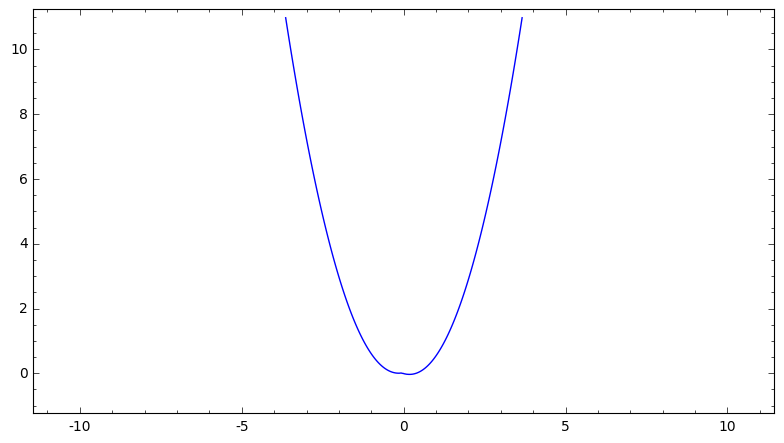

In [318]:
R.<x,y,z,t,u0,u1,u2>=QQ[]
surface = z-(x^2+x*y+y^4)
#s = singular.eval
#s('LIB "surf.lib";')
#s("ring r = 0,(x,y,z),dp;")
#s("surfer(" + str(surface) + ")")

surface_h = surface.homogenize(t)

X = matrix(R, [[x], [y], [z], [t]])
U = matrix(R, [[u0],[u1],[u2]])

# projection:
s=.05
r=10
proj_matrix = matrix(QQ, [[1,s,0,0],[0,s,1,0],[0,0,0,1]])
print(proj_matrix)

incidence = surface_h + ideal((proj_matrix*X).augment(U).minors(2))
incidence = surface_h + ideal(((proj_matrix*X)-U).list())

ramification = incidence + ideal(jacobian(incidence.gens(),(x,y,z,t)).minors(4))

outline = ramification.saturation(ideal(x,y,z,t))[0]
outline = outline.elimination_ideal((x,y,z,t))

print(outline)
outline=outline.subs(u2=1)
(outline.change_ring(QQ[u0,u1])).plot(plot_points=1000)#,algorithm='surf')

In [ ]:
(outline.change_ring(QQ[u0,u1])).plot

In [ ]:
(outline.change_ring(QQ[u0,u1])).plot

In [ ]:
outline=outline.subs

In [142]:
sines = [plot(c*sin(x), (-2*pi,2*pi), color=Color(c,0,0), ymin=-1, ymax=1) for c in sxrange(0,1,.2)]
a = animate(sines)
a.save('test_animation.gif')

In [150]:
R.<x,y>=QQ[]
curve = ideal(y-x^3)
curve.plot(algorithm="surf",linewidth=50)

In [328]:
# condition for a polynomial to have 2+2 multiplicity/ have 3 multiplicity/ 

# for surfaces: conditions for a polynomial to have 4 multiplicity (flecnodal)
# have 3+2, 2+2+2 (ok). Intersection with plane: 3+ramification on y, 2+2+ramification on y

In [81]:
# subresultant
R.<s,t>=QQ[]

poly0 = s^2*t^4+t+3 
poly1 = s*t^3+s*t^2

poly0=poly0.polynomial(t)
poly1=poly1.polynomial(t)


print subresultant_2(poly0,poly1)

#show(poly.sylvester_matrix(poly.derivative(t), t))

subres = (poly.sylvester_matrix(poly.derivative(t), t)).delete_rows([2,6])
subres = subres.delete_columns([6])
#show(subres)

subres.nrows(),subres.ncols()

condition1 = subres.delete_columns([5]).determinant()
condition2 = subres.delete_columns([4]).determinant()

(3*s^2, s^2, s^4)


In [67]:
M=poly0.sylvester_matrix(poly1)
M.delete_rows?

In [ ]:
(poly0.sylvester_matrix(poly1)).delete_rows

In [62]:
poly0.sylvester_matrix(poly1).delete_rows(?)

SyntaxError: invalid syntax (<ipython-input-62-7debf33a83f8>, line 1)

In [ ]:
poly0.sylvester_matrix(poly1).delete_rows

In [4]:
R.<d>=QQ[]
S.<t1,t2>=R[]

In [20]:
d*t1*((d-1)*t1+t2)*((d-2)*t1+2*t2)#*((d-3)*t1+3*t2)

(d^3 - 3*d^2 + 2*d)*t1^3 + (3*d^2 - 4*d)*t1^2*t2 + 2*d*t1*t2^2

TypeError: no conversion of this ring to a Singular ring defined

In [227]:
load("nodal3.sobj")

Ideal (a3^3 - 4*a2*a3*a4 + 8*a1*a4^2, a2*a3^2 - 4*a2^2*a4 + 2*a1*a3*a4 + 16*a0*a4^2, a1*a3^2 - 4*a1*a2*a4 + 8*a0*a3*a4, a0*a3^2 - a1^2*a4, a1^2*a3 - 4*a0*a2*a3 + 8*a0*a1*a4, a1^2*a2 - 4*a0*a2^2 + 2*a0*a1*a3 + 16*a0^2*a4, a1^3 - 4*a0*a1*a2 + 8*a0^2*a3) of Multivariate Polynomial Ring in a0, a1, a2, a3, a4 over Rational Field